# 2 — Préparation des données · Segment : Comptes joints

**Objectif** : dérouler le chapitre 2 du cours sur le segment *comptes joints* (`nb_tiers > 1`),
avant l'analyse exploratoire (ch. 3) et la discrétisation (ch. 4).

| § | Thème | Traitement appliqué ici |
|---|-------|-------------------------|
| 2.1 | Sources de données | inventaire des variables disponibles |
| 2.2 | Valeurs manquantes | analyse, puis **missing conservé comme modalité** |
| 2.3 | Outliers | valeurs aberrantes → manquant ; valeurs extrêmes → winsorisation |
| 2.4 | Feature engineering | ratios |
| 2.5 | Variables interdites | repérage et exclusion |
| — | Présélection | exclusion des variables quasi vides, quasi constantes, non discriminantes ou redondantes |

> Ce notebook est un **rapport lisible** : les calculs sont délégués à `utils/stats_descriptives.py`
> et `utils/exploration.py`. Seuls les paramètres et les décisions figurent ici.

## 0. Imports et configuration

In [1]:
import sys
from pathlib import Path

# Racine du projet : ce notebook est rangé dans Segmentation_joint/
ROOT = Path.cwd().parent if Path.cwd().name == "Segmentation_joint" else Path.cwd()
sys.path.insert(0, str(ROOT))

import polars as pl
import matplotlib.pyplot as plt

from utils.binning import iv_ranking
from utils.exploration import (
    nan_to_null, outlier_report, exporter_excel,
    constant_report, paires_redondantes, cramers_v_matrix, paires_fortes, preselection_variables,
)
from utils.stats_descriptives import (
    profil_segment, grille_quanti, plot_taux_missing,
    table_missing, plot_missing_tdr, missing_en_modalite,
    valeurs_aberrantes, winsoriser, ajouter_ratios, reperer_variables, bilan_variables,
)
from utils.modele import decoupage_apprentissage_test, bilan_echantillons
from utils.synthese import afficher, constat_manquants, constat_outliers, constat_preselection

%matplotlib inline
plt.rcParams["figure.dpi"] = 120
pl.Config.set_tbl_rows(40)

polars.config.Config

In [2]:
BASE     = ROOT.parent / "data/segments/joint/base_joint.parquet"
SORTIE   = ROOT.parent / "data/segments/joint/base_joint_prep.parquet"

TARGET   = "ddefaut_ndb"   # variable cible (0/1)
ID_COL   = "gdt"           # identifiant
DATE_COL = "datdelhis"     # date d'observation

# Colonnes techniques, hors du champ des variables explicatives
EXCLUDE  = [ID_COL, TARGET, DATE_COL, "segment", "SelectionProb", "SamplingWeight",
            "type_PM_PP", "code_marche_v2", "echantillon"]

# Une variable numérique de plus de MAX_MODALITES valeurs distinctes est traitée comme continue
MAX_MODALITES = 15

# Découpage apprentissage / test (cours 1.5) ; l'échantillon Out-of-Time sera une base fournie séparément
PART_TEST = 0.20
SEED      = 42

## 1. Chargement

La base du segment est produite par le notebook `0 - Segmentation_exploration.ipynb`.
Les `NaN` des colonnes flottantes sont convertis en `null` : sans cela ils ne seraient pas
comptés comme manquants.

In [3]:
if not BASE.exists():
    raise FileNotFoundError(f"{BASE} introuvable : exécuter d'abord le notebook de segmentation.")

df = nan_to_null(pl.read_parquet(BASE))

manquantes = [c for c in (TARGET, ID_COL, DATE_COL) if c and c not in df.columns]
assert not manquantes, f"Colonnes absentes de la base : {manquantes}"

EXCLUDE = [c for c in EXCLUDE if c in df.columns]

print(f"Base chargée : {df.height} lignes, {df.width} colonnes")

Base chargée : 58947 lignes, 193 colonnes


## 1.5 Découpage apprentissage / test

Cours 1.5 : toutes les transformations (bornes de winsorisation, présélection, découpages, modèle) sont **apprises sur
l'apprentissage seul**, puis appliquées telles quelles au test. Le test sert à mesurer la performance hors échantillon
au chapitre 5.

- Tirage **par dossier** (`gdt`, cours 1.5.5) : un dossier observé plusieurs mois est tout entier du même côté ;
- stratifié sur la cible du dossier, pour un taux de défaut identique des deux côtés ;
- 80 % / 20 %.

L'échantillon **Out-of-Time** sera une base fournie séparément : il sera noté avec la chaîne figée en fin de
chapitre 6 (`scorer_nouvelle_base`), sans rien réestimer.

In [4]:
df = decoupage_apprentissage_test(df, id_col=ID_COL, target=TARGET, part_test=PART_TEST, seed=SEED)
TRAIN = pl.col("echantillon") == "apprentissage"
EXCLUDE = list(dict.fromkeys(EXCLUDE + ["echantillon"]))   # colonne technique
bilan_echantillons(df, TARGET)

echantillon,n,n_defaut,taux_defaut,part
str,u32,f64,f64,f64
"""apprentissage""",47156,228.0,0.004835,0.799973
"""test""",11791,56.0,0.004749,0.200027


## 2.1 Sources de données

Inventaire de ce qui est disponible : volume, taux de défaut, période couverte, et répartition
des variables par nature.

Une variable connue seulement *après* `datdelhis` doit être écartée (fuite d'information).

| Famille | Exemples | Source | Connue à `datdelhis` ? |
|---------|----------|--------|------------------------|
| Signalétique du dossier | nombre de titulaires, axe de clientèle, CSP | production interne (fichier clients) | oui |
| Relation bancaire | ancienneté, nombre de produits détenus | production interne | oui |
| Fonctionnement du compte | soldes, mouvements, découvert, ratios de solde | production interne (comptes courants) | oui, sur les mois précédant l'observation |
| Engagements | encours de crédit immobilier, conso, revolving, MLT | production interne (crédits) | oui |
| Incidents | jours d'arriérés, défauts des derniers mois, interdit bancaire | production interne et fichiers Banque de France (FICP / FCC) | oui (historique arrêté avant l'observation) |

Aucune donnée externe payante ni d'open banking n'est identifiée dans la base : toutes les familles proviennent
du système d'information interne (**à confirmer avec le dictionnaire des données**). Les variables propres aux
clients professionnels (`CODNAF2`, `CODETAJUR`, `flux_pro`, `RATIO_LITIGES_vs_CA`…) sont vides pour ce segment de
particuliers et sont retirées à la présélection. `DATE_DERNIER_DFO` s'arrête au 31/12/2020, avant la première observation : pas de fuite
(notebook 0, § 1.4).

In [5]:
profil_segment(df, target=TARGET, id_col=ID_COL, date_col=DATE_COL)

n_total,n_defaut,n_sain,taux_defaut,date_min,date_max
i64,i64,i64,f64,str,str
58947,284,58663,0.004818,"""2021-01-01""","""2021-04-01"""


In [6]:
VARS        = [c for c, t in df.schema.items() if c not in EXCLUDE and not t.is_temporal()]
VARS_QUANTI = [c for c in VARS if df.schema[c].is_numeric()]
VARS_QUALI  = [c for c in VARS if c not in VARS_QUANTI]
VARS_CONTINUES = [c for c in VARS_QUANTI if df[c].n_unique() > MAX_MODALITES]

print(f"{len(VARS)} variables explicatives candidates")
print(f"  - {len(VARS_QUANTI)} quantitatives, dont {len(VARS_CONTINUES)} continues (> {MAX_MODALITES} valeurs distinctes)")
print(f"  - {len(VARS_QUALI)} qualitatives")

pl.DataFrame({"dtype": [str(df.schema[c]) for c in VARS]}).group_by("dtype").len().sort("len", descending=True)

182 variables explicatives candidates
  - 155 quantitatives, dont 94 continues (> 15 valeurs distinctes)
  - 27 qualitatives


dtype,len
str,u32
"""Float64""",155
"""String""",19
"""Boolean""",6
"""Enum(categories=['18-25', '25-…",1
"""Enum(categories=['<1an', '1-2a…",1


## 2.2 Valeurs manquantes

**Principe du cours** : le manquant n'est ni imputé ni supprimé, il est **conservé comme une modalité
à part entière**. L'absence d'information est souvent elle-même porteuse de risque.

L'analyse ci-dessous sert à le vérifier variable par variable : on compare le taux de défaut des
dossiers manquants à celui des dossiers renseignés.

- `ecart_tdr` : taux de défaut des manquants − taux de défaut des renseignés ;
- `pvalue` : test du Chi² d'indépendance entre l'indicatrice « manquant » et la cible.

In [7]:
tab_missing = table_missing(df.filter(TRAIN), target=TARGET, columns=VARS)   # apprentissage

n_avec = tab_missing.filter(pl.col("n_missing") > 0).height
print(f"{n_avec} variables sur {len(VARS)} comportent au moins un manquant")

tab_missing.filter(pl.col("n_missing") > 0)

38 variables sur 182 comportent au moins un manquant


variable,dtype,n_missing,taux_missing,tdr_missing,tdr_renseigne,ecart_tdr,pvalue
str,str,i64,f64,f64,f64,f64,f64
"""AGE_PM_EN_MOIS""","""Float64""",47156,1.0,0.004835,null,null,null
"""CODACVPRO_modif""","""Float64""",47156,1.0,0.004835,null,null,null
"""CODNAF2""","""String""",47156,1.0,0.004835,null,null,null
"""CODETAJUR""","""String""",47156,1.0,0.004835,null,null,null
"""CRTOC_TOK_0010""","""String""",47156,1.0,0.004835,null,null,null
"""RATIO_LITIGES_vs_CA""","""Float64""",47156,1.0,0.004835,null,null,null
"""flux_pro""","""String""",47156,1.0,0.004835,null,null,null
"""MVTAFF_STABILITE_2T_vs_12M""","""Float64""",45488,0.964628,0.004705,0.008393,-0.003689,0.050773
"""CODITDBDF_PRO""","""String""",45424,0.963271,0.004711,0.008083,-0.003372,0.070435


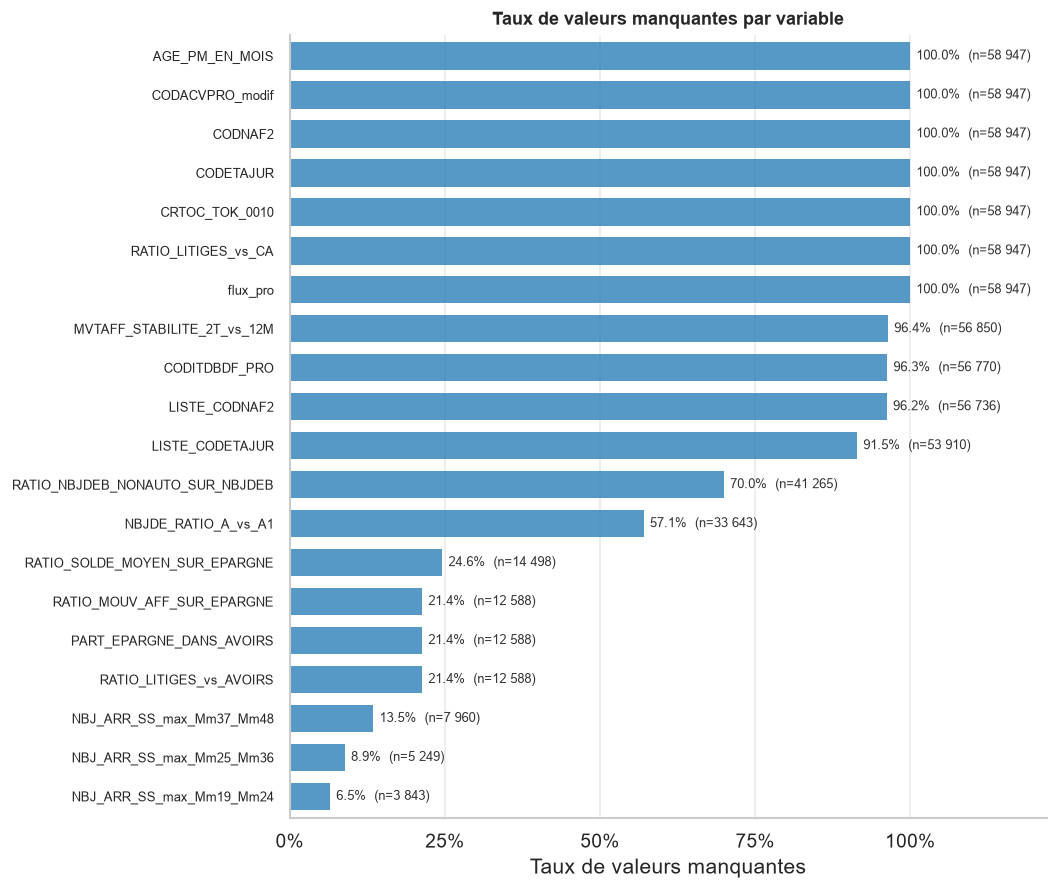

In [8]:
SEUIL_AFFICHAGE = 0.05   # seules les variables au-delà de ce taux de manquants sont tracées

fig = plot_taux_missing(df, columns=VARS, seuil_affichage=SEUIL_AFFICHAGE, top_n=30)
plt.show()

### Le manquant est-il informatif ?

Variables où le taux de défaut des manquants s'écarte le plus de celui des renseignés.

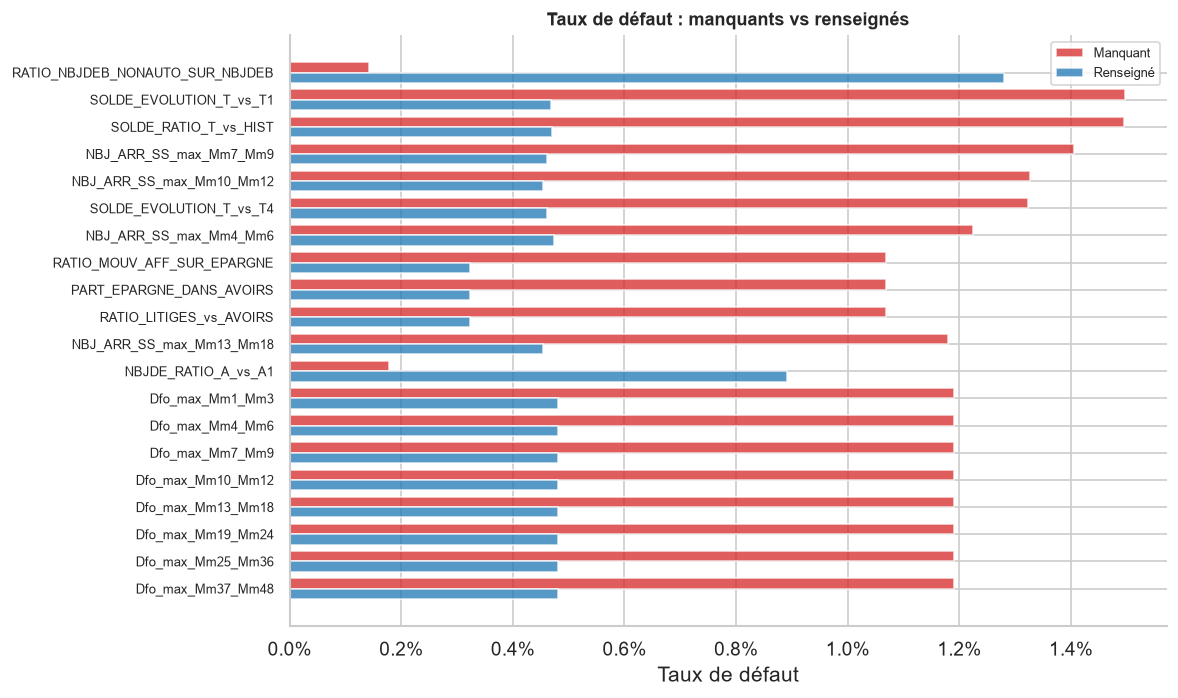

In [9]:
fig = plot_missing_tdr(tab_missing, top_n=20, n_min=30)
plt.show()

In [10]:
ALPHA = 0.05

informatifs = tab_missing.filter(pl.col("pvalue") < ALPHA).sort(pl.col("ecart_tdr").abs(), descending=True)
print(f"{informatifs.height} variables dont le manquant est lié au défaut (p < {ALPHA})")
informatifs

18 variables dont le manquant est lié au défaut (p < 0.05)


variable,dtype,n_missing,taux_missing,tdr_missing,tdr_renseigne,ecart_tdr,pvalue
str,str,i64,f64,f64,f64,f64,f64
"""RATIO_NBJDEB_NONAUTO_SUR_NBJDE…","""Float64""",33012,0.700059,0.001424,0.012797,-0.011373,2.5164e-59
"""SOLDE_EVOLUTION_T_vs_T1""","""Float64""",735,0.015587,0.014966,0.004675,0.010291,0.000197
"""SOLDE_RATIO_T_vs_HIST""","""Float64""",602,0.012766,0.01495,0.004704,0.010246,0.000949
"""NBJ_ARR_SS_max_Mm7_Mm9""","""Float64""",1138,0.024133,0.01406,0.004607,0.009453,0.000015
"""NBJ_ARR_SS_max_Mm10_Mm12""","""Float64""",1582,0.033548,0.013274,0.004542,0.008732,0.000002
"""SOLDE_EVOLUTION_T_vs_T4""","""Float64""",1209,0.025638,0.013234,0.004614,0.00862,0.00005
"""NBJ_ARR_SS_max_Mm4_Mm6""","""Float64""",653,0.013848,0.012251,0.004731,0.00752,0.013621
"""RATIO_MOUV_AFF_SUR_EPARGNE""","""Float64""",10099,0.214162,0.010694,0.003238,0.007456,2.2125e-21
"""PART_EPARGNE_DANS_AVOIRS""","""Float64""",10099,0.214162,0.010694,0.003238,0.007456,2.2125e-21


### Variables presque entièrement manquantes

Elles sont signalées ici et **retirées à l'étape de présélection**, en fin de notebook.

In [11]:
SEUIL_QUASI_VIDE = 0.95

tab_missing.filter(pl.col("taux_missing") >= SEUIL_QUASI_VIDE)

variable,dtype,n_missing,taux_missing,tdr_missing,tdr_renseigne,ecart_tdr,pvalue
str,str,i64,f64,f64,f64,f64,f64
"""AGE_PM_EN_MOIS""","""Float64""",47156,1.0,0.004835,null,null,null
"""CODACVPRO_modif""","""Float64""",47156,1.0,0.004835,null,null,null
"""CODNAF2""","""String""",47156,1.0,0.004835,null,null,null
"""CODETAJUR""","""String""",47156,1.0,0.004835,null,null,null
"""CRTOC_TOK_0010""","""String""",47156,1.0,0.004835,null,null,null
"""RATIO_LITIGES_vs_CA""","""Float64""",47156,1.0,0.004835,null,null,null
"""flux_pro""","""String""",47156,1.0,0.004835,null,null,null
"""MVTAFF_STABILITE_2T_vs_12M""","""Float64""",45488,0.964628,0.004705,0.008393,-0.003689,0.050773
"""CODITDBDF_PRO""","""String""",45424,0.963271,0.004711,0.008083,-0.003372,0.070435


### Constat

In [12]:
afficher(constat_manquants(tab_missing, alpha=ALPHA, seuil_quasi_vide=SEUIL_QUASI_VIDE))

- **38** variables sur 182 comportent au moins un manquant ; taux de manquants médian parmi elles : **7,7%**.
- **10** variables ont au moins 95% de manquants : `AGE_PM_EN_MOIS`, `CODACVPRO_modif`, `CODNAF2`, `CODETAJUR`, `CRTOC_TOK_0010`, `RATIO_LITIGES_vs_CA`, `flux_pro`, `MVTAFF_STABILITE_2T_vs_12M` … (+2 autres). Elles sont retirées à la présélection.
- **18** variables ont un manquant lié au défaut (Chi², p < 0,05) : chez **15** d'entre elles les dossiers manquants sont *plus* risqués que les renseignés, chez **3** ils sont *moins* risqués.

Manquants les plus informatifs :

| Variable | Taux de manquants | TDR manquants | TDR renseignés |
|---|---|---|---|
| `RATIO_NBJDEB_NONAUTO_SUR_NBJDEB` | 70,0% | 0,14% | 1,28% |
| `SOLDE_EVOLUTION_T_vs_T1` | 1,6% | 1,50% | 0,47% |
| `SOLDE_RATIO_T_vs_HIST` | 1,3% | 1,50% | 0,47% |
| `NBJ_ARR_SS_max_Mm7_Mm9` | 2,4% | 1,41% | 0,46% |
| `NBJ_ARR_SS_max_Mm10_Mm12` | 3,4% | 1,33% | 0,45% |

### Décision

- **Aucune ligne n'est supprimée** pour cause de valeurs manquantes. Seules les variables presque
  entièrement manquantes sont retirées, à l'étape de présélection.
- Variables **qualitatives** : le manquant devient la modalité explicite `"missing"`.
- Variables **quantitatives** : le manquant reste `null` ; il formera une classe à part lors de la
  discrétisation (ch. 4), avec son propre WOE.

**Lecture métier** :

- Les variables **entièrement vides** (10 variables à ≥ 95 % de manquants) sont des informations de clientèle
  professionnelle (code NAF, forme juridique, flux d'affaires, litiges rapportés au chiffre d'affaires) ou des
  informations individuelles sans version agrégée pour les dossiers joints (CSP `CODACVPRO_modif`, `AGE_PM_EN_MOIS`).
  Leur absence est structurelle : elles ne portent aucune information sur ce segment.
- **17 variables ont un manquant lié au défaut**. Chez 15 d'entre elles, le manquant est **plus risqué** : ce sont
  surtout les historiques d'arriérés (`NBJ_ARR_SS_max_Mm7_Mm9`, `…Mm10_Mm12`…) et les évolutions de solde
  (`SOLDE_EVOLUTION_T_vs_T1`, `SOLDE_RATIO_T_vs_HIST`), absents quand le dossier n'a pas d'historique sur la fenêtre :
  relation récente, donc moins connue et plus risquée (environ 1,4 % de défaut contre 0,46 %). C'est un manquant
  **MNAR**, qui justifie de le garder comme modalité.
- Pour `RATIO_NBJDEB_NONAUTO_SUR_NBJDEB` (70 % de manquants), le manquant est au contraire **beaucoup moins risqué**
  (0,15 % contre 1,28 %) : le ratio n'est pas défini quand le compte n'a eu aucun jour débiteur. Le manquant signifie
  ici « jamais à découvert ».

In [13]:
df_prep = missing_en_modalite(df, columns=VARS_QUALI)

reste = sum(df_prep[c].null_count() for c in VARS_QUALI)
print(f"Manquants restants dans les variables qualitatives : {reste}")

Manquants restants dans les variables qualitatives : 0


## 2.3 Outliers

On distingue deux cas, traités différemment :

1. **Valeurs aberrantes** : impossibles d'un point de vue métier (âge négatif, taux supérieur à 100 %…).
   Ce sont des erreurs : elles sont remplacées par un manquant.
2. **Valeurs extrêmes** : plausibles mais très éloignées du reste de la distribution.
   Elles sont détectées (règle IQR) puis écrêtées par winsorisation.

### Valeurs aberrantes

Aucune plage admissible n'est renseignée à ce stade (`PLAGES` vide) : le rapport est vide. Les âges sont exclus
(§ 2.5) ; **à compléter si le dictionnaire des données précise des domaines** (taux bornés à 100 %, durées
positives…).

In [14]:
# {variable: (min admissible, max admissible)} ; None = pas de borne
PLAGES = {
    # "AGE_PM_EN_MOIS": (0, None),
}
PLAGES = {c: p for c, p in PLAGES.items() if c in df_prep.columns}

df_prep, rapport_aberrantes = valeurs_aberrantes(df_prep, PLAGES)
rapport_aberrantes

variable,min_admissible,max_admissible,n_aberrantes,taux_aberrantes
str,f64,f64,i64,f64


### Valeurs extrêmes — détection

Règle IQR : une valeur est extrême si elle sort de `[Q1 − k·IQR ; Q3 + k·IQR]`.
On prend `k = 3` (valeurs « très » extrêmes) plutôt que 1,5 : les variables de montants sont
naturellement asymétriques et la règle à 1,5 en signalerait une part trop importante.

In [15]:
K_IQR = 3

rapport_outliers = (
    outlier_report(df_prep.filter(TRAIN), columns=VARS_CONTINUES, method="iqr", k=K_IQR)
    .sort("taux_outliers", descending=True, nulls_last=True)
)
rapport_outliers.filter(pl.col("n_outliers") > 0)

variable,n_outliers,taux_outliers,borne_basse,borne_haute
str,i64,f64,f64,f64
"""engagement_immo__crelog""",9987,0.211786,-48149.88,64199.84
"""CRTAR_IND_0036""",9672,0.205106,0.0,0.0
"""solde_debiteur""",9624,0.204089,-2928.0,2196.0
"""CRTAV_IND_0165""",9022,0.191322,-477729.0,636972.0
"""CRTAD_IND_0015""",7690,0.163076,-6.0,8.0
"""RATIO_SOLDE_MOYEN_SUR_EPARGNE""",5707,0.160643,-6.508856,8.965569
"""engagement_credit_perso""",6681,0.141679,0.0,0.0
"""SOLDE_PENTE_3T""",6588,0.139707,-183084.0,193750.5
"""SOLDE_PENTE_4T""",6383,0.135359,-148882.0,172882.1


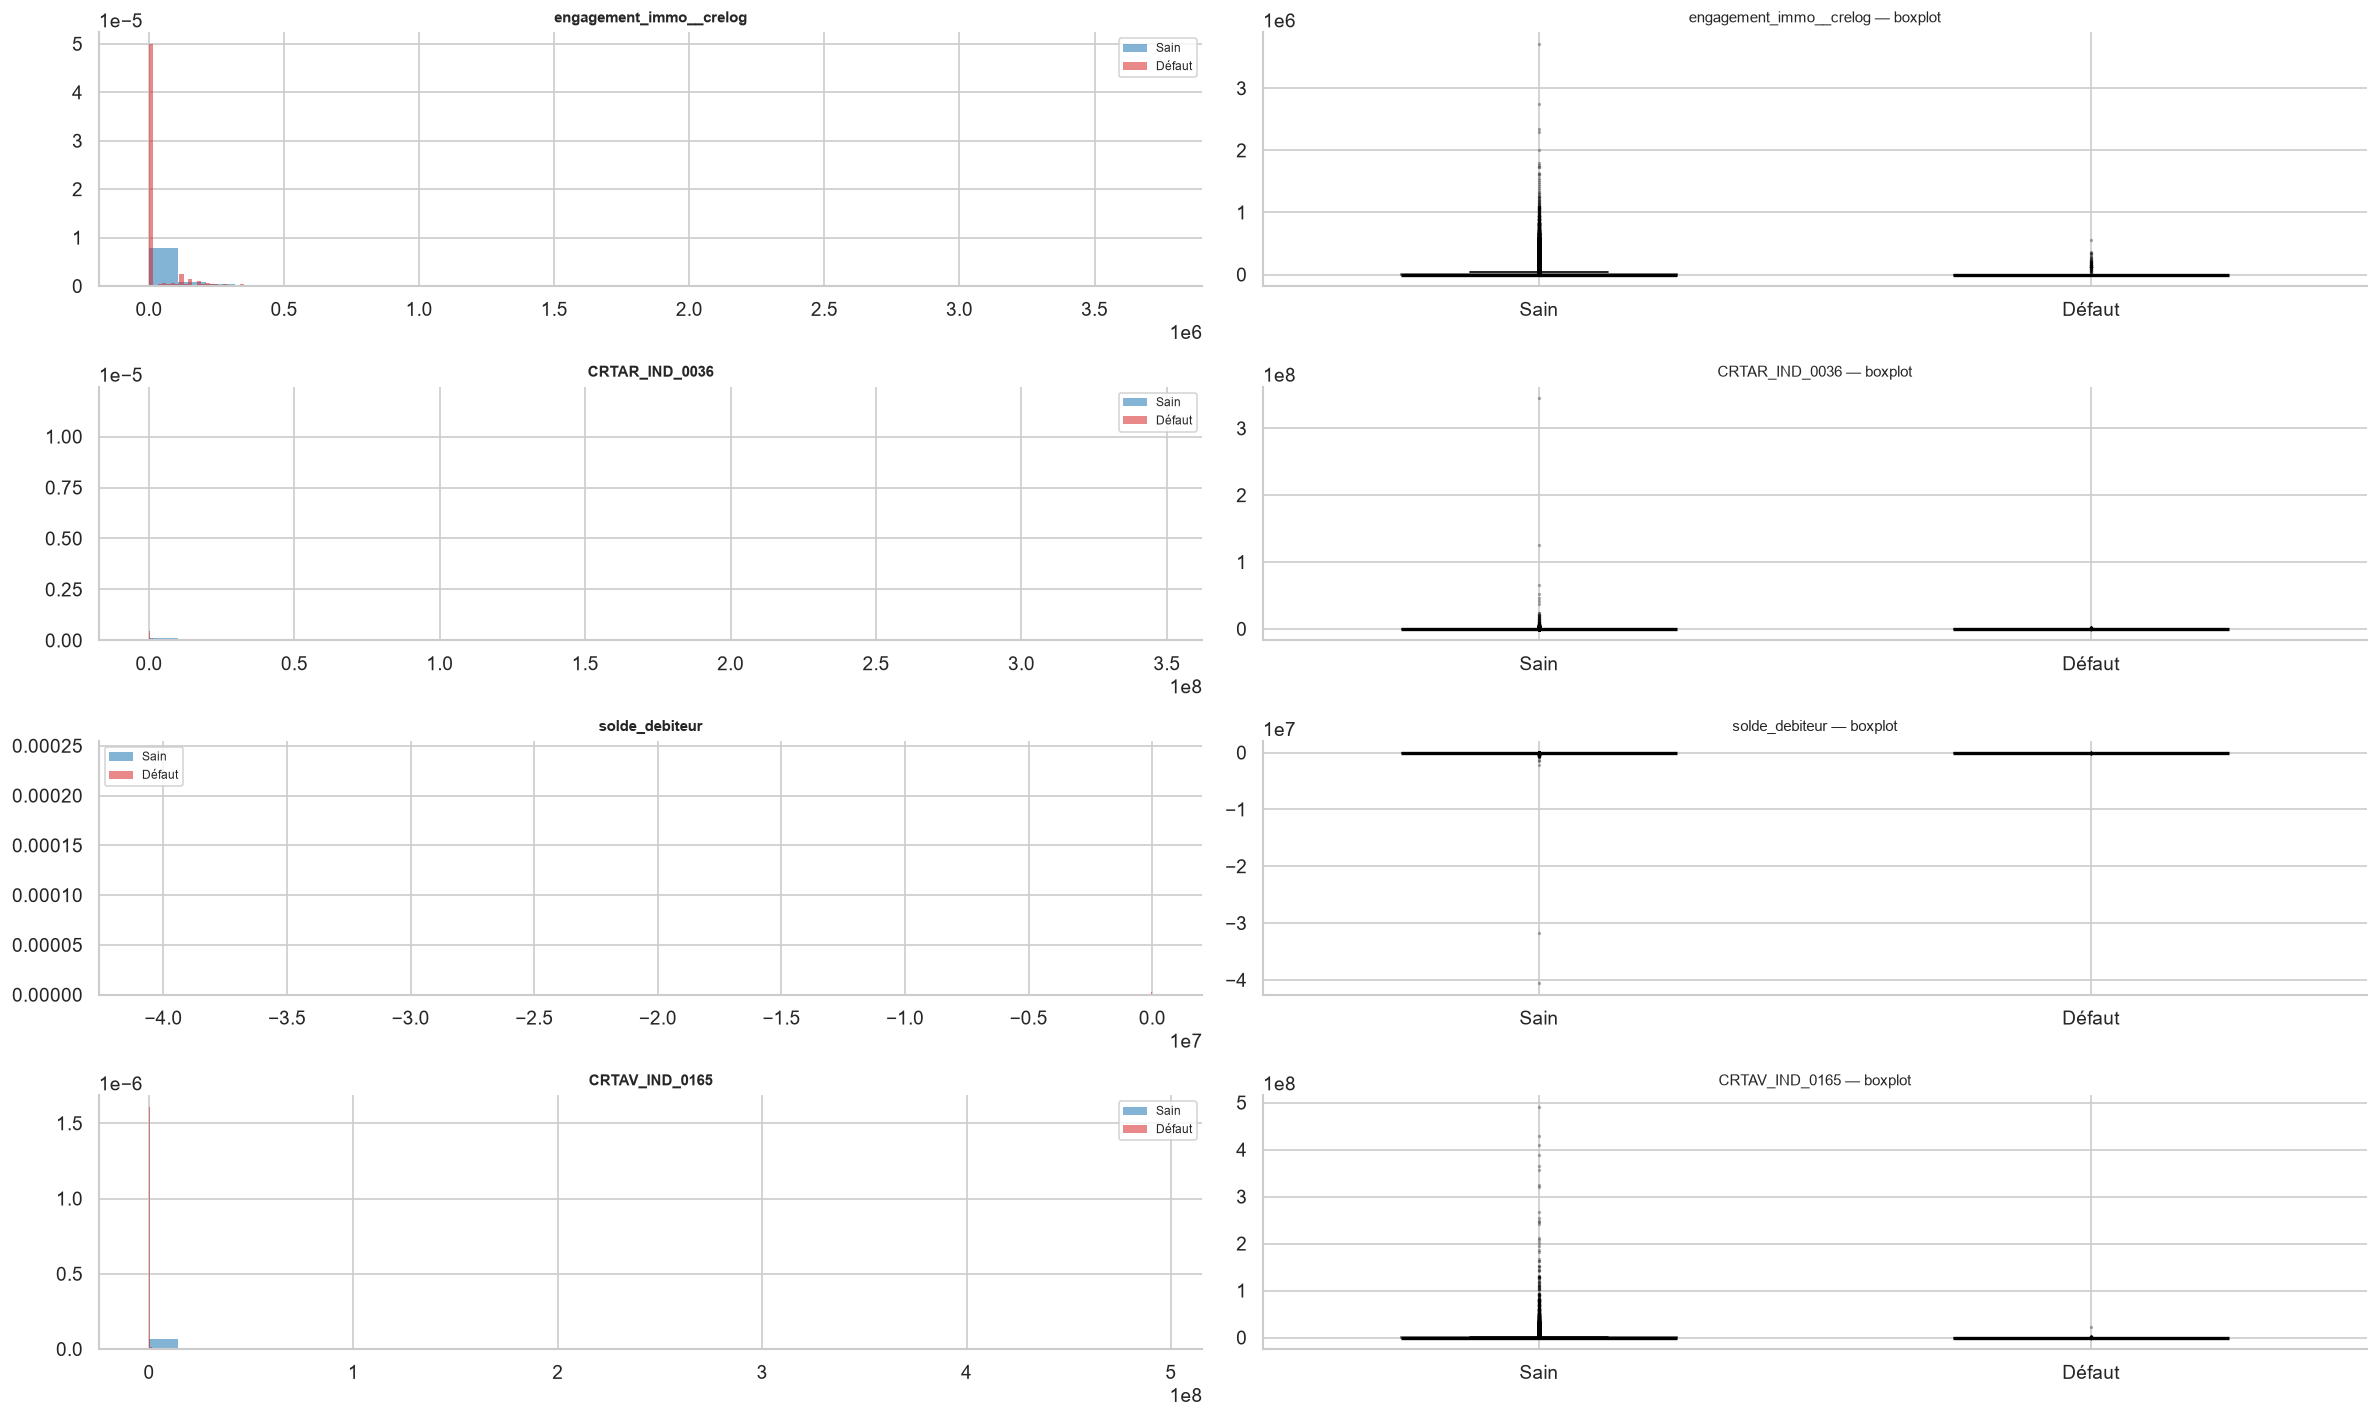

In [16]:
# Distributions des variables les plus touchées
VARS_OUTLIERS_PLOT = rapport_outliers.filter(pl.col("n_outliers") > 0)["variable"].head(4).to_list()

if VARS_OUTLIERS_PLOT:
    fig = grille_quanti(df_prep, variables=VARS_OUTLIERS_PLOT, target=TARGET)
    plt.show()

### Valeurs extrêmes — traitement

Winsorisation aux quantiles 1 % et 99 % : les valeurs au-delà sont ramenées à la borne.
Aucune observation n'est supprimée, ce qui préserve le volume de défauts.

Deux remarques :

- La discrétisation (ch. 4) absorbe de toute façon les extrêmes dans les classes de bord : la
  winsorisation compte surtout pour les statistiques descriptives, les corrélations de Pearson et
  les ratios construits ensuite.
- Les bornes sont estimées sur l'**apprentissage** seul, puis réappliquées à toute la base
  (`winsoriser(..., bornes=bornes)`), conformément au cours 1.5.4.

Une variable dont les deux bornes coïncident (comptage presque toujours nul) n'est pas modifiée.

In [17]:
P_BAS, P_HAUT = 0.01, 0.99

# Bornes apprises sur l'apprentissage, puis appliquées à toute la base
_, bornes = winsoriser(df_prep.filter(TRAIN), columns=VARS_CONTINUES, p_bas=P_BAS, p_haut=P_HAUT)
df_prep, bornes = winsoriser(df_prep, columns=VARS_CONTINUES, bornes=bornes)

print(f"{bornes['winsorisee'].sum()} variables winsorisées sur {len(VARS_CONTINUES)}")
bornes.sort("taux_ecrete", descending=True, nulls_last=True)

80 variables winsorisées sur 94


variable,borne_basse,borne_haute,n_bas,n_haut,taux_ecrete,winsorisee
str,f64,f64,i64,i64,f64,bool
"""SOLDE_PENTE_5T""",-656616.45,1.08985e6,606,604,0.020527,true
"""CRTAD_AG_SOLDE_T4""",-72499.0,7813499.5,600,601,0.020374,true
"""SOLDE_PENTE_4T""",-847399.8,1.2263e6,596,603,0.02034,true
"""RATIO_SOLDE_MOYEN_SUR_EPARGNE""",-15.260312,663.838484,457,442,0.020225,true
"""CRTAD_IND_0038""",-102000.0,1.5234e7,589,594,0.020069,true
"""CRTAD_AG_SOLDE_T2""",-54833.0,8.535833e6,591,590,0.020035,true
"""SOLDE_RATIO_T_vs_HIST""",-3.269666,13.800879,586,579,0.020025,true
"""CRTAD_AG_SOLDE_T3""",-66666.0,8.215332e6,588,592,0.020018,true
"""CRTAD_AG_SOLDE_T""",-53500.0,8880499.5,590,588,0.019984,true


### Constat

In [18]:
afficher(constat_outliers(rapport_outliers, bornes, k=K_IQR))

- Règle IQR (k = 3,0) : **88** variables continues sur 94 présentent des valeurs extrêmes ; les plus touchées : `engagement_immo__crelog`, `CRTAR_IND_0036`, `solde_debiteur`, `CRTAV_IND_0165`, `CRTAD_IND_0015` (jusqu'à 21,2% des valeurs renseignées).
- Winsorisation : **80** variables écrêtées, part médiane des valeurs ramenées à la borne : **1,0%**. **14** variables non modifiées (bornes confondues, typiquement un comptage presque toujours nul).

**Lecture** : 88 variables continues sur 94 ont des valeurs extrêmes au sens de l'IQR (k = 3), ce qui est
attendu pour des montants très asymétriques (encours immobilier, épargne `CRTAV_IND_0165`, soldes). Pour plusieurs
**comptages presque toujours nuls** (`CRTAR_IND_0036`, `NBJ_ARR_SS_*`), l'IQR vaut 0 : toute valeur non nulle est
signalée comme « extrême », alors qu'elle porte justement l'information de risque. La winsorisation à 1 % – 99 % ne
touche que 1 % des valeurs en médiane et laisse ces comptages intacts (bornes confondues) : aucune information de
risque n'est écrasée.

## 2.4 Feature engineering

Le cours souligne que ratios, tendances et agrégats temporels apportent souvent plus de pouvoir
discriminant que le choix de l'algorithme. Les ratios sont construits **après** winsorisation, pour ne pas
être dominés par les extrêmes. Un ratio dont le dénominateur est nul ou manquant est manquant : il formera la
classe « missing » à la discrétisation.

Les variables créées passent ensuite par la même présélection que les variables d'origine.

**Aucun ratio supplémentaire n'est créé** (`RATIOS` vide) : la base contient déjà les principaux ratios métier
et variables de tendance (cours 2.4.1 – 2.4.2) :

| Variable existante | Sens métier |
|--------------------|-------------|
| `RATIO_SOLDE_MOYEN_SUR_EPARGNE` | trésorerie courante rapportée à l'épargne |
| `RATIO_MOUV_AFF_SUR_EPARGNE`, `PART_EPARGNE_DANS_AVOIRS` | poids de l'épargne dans les avoirs |
| `SOLDE_EVOLUTION_T_vs_T1`, `SOLDE_EVOLUTION_T_vs_T4`, `SOLDE_RATIO_T_vs_HIST` | tendance du solde (dégradation récente) |
| `SOLDE_PENTE_3T` … `5T`, `SOLDE_VOLATILITE_3T` | pente et volatilité du solde |
| `NBJDE_RATIO_A_vs_A1`, `NBECR_EVOLUTION_A_vs_A1` | évolution sur un an des jours débiteurs et des écritures |

**Piste non exploitée, propre aux dossiers joints** (notebook 0, § 1.5) : le **total du foyer** (médiane × nombre de
titulaires) et l'**écart entre membres** (`_max − _min`), qui peut révéler un membre en difficulté. À tester si l'on
cherche du Gini supplémentaire.

In [19]:
# {nom de la nouvelle variable: (numérateur, dénominateur)}
RATIOS = {
    # "RATIO_EXEMPLE": ("NUMERATEUR", "DENOMINATEUR"),
}
RATIOS = {nom: (num, den) for nom, (num, den) in RATIOS.items() if num in df_prep.columns and den in df_prep.columns}

df_prep = ajouter_ratios(df_prep, RATIOS)
VARS_CREEES = list(RATIOS)
print(f"{len(VARS_CREEES)} variables créées : {VARS_CREEES}")

0 variables créées : []


## 2.5 Variables interdites, RGPD et AI Act

Certaines variables ne peuvent pas entrer dans un score d'octroi, quel que soit leur pouvoir
discriminant : données sensibles au sens du RGPD (art. 9 : origine, opinions, religion, santé…) et
critères de discrimination prohibés (sexe, nationalité…). Le scoring de crédit étant un système
**à haut risque** au sens de l'AI Act, chaque variable retenue doit en outre pouvoir être justifiée.

Le repérage ci-dessous se fait **sur le nom des colonnes** : c'est un premier filtre, qui ne remplace
pas la relecture du dictionnaire de données.

In [20]:
MOTIFS_INTERDITS = {
    "age":           ["AGE_PP_EN_MOIS", "AGE_PM_EN_MOIS", "age_ans"]
}

reperage = reperer_variables(df_prep.select(VARS), MOTIFS_INTERDITS)
reperage

variable,famille,motif,dtype
str,str,str,str
"""AGE_PP_EN_MOIS""","""age""","""AGE_PP_EN_MOIS""","""Float64"""
"""AGE_PM_EN_MOIS""","""age""","""AGE_PM_EN_MOIS""","""Float64"""
"""age_ans""","""age""","""age_ans""","""Float64"""


### Décision

Par défaut, toutes les variables repérées sont exclues. Ajuster la liste après relecture :
retirer les faux positifs, ajouter les variables interdites que le nom ne trahit pas.

| Variable | Motif | Justification |
|----------|-------|---------------|
| `AGE_PP_EN_MOIS`, `AGE_PM_EN_MOIS`, `age_ans`, `age` | âge | critère de discrimination prohibé (Code pénal, art. 225-1) ; le scoring de crédit est un système à haut risque (AI Act, annexe III) et chaque variable doit être justifiable. L'âge est exclu **en entier** (variable brute et tranches construites au notebook 0), sinon il reviendrait par une version dérivée (cours 2.5.3, variables proxy). |

Le sexe, la nationalité et les données de santé ne figurent pas dans la base (**à confirmer sur le dictionnaire**).
Le notebook 0 envisageait de comparer le Gini avec et sans l'âge : ce test reste possible au ch. 5, mais l'exclusion
est le choix par défaut, le plus défendable en comité.

In [21]:
VARS_INTERDITES = reperage["variable"].unique(maintain_order=True).to_list()
# Tranche d'âge construite au notebook 0 : son nom est trop court pour le repérage automatique
VARS_INTERDITES += [c for c in ["age"] if c in df_prep.columns]

df_prep = df_prep.drop(VARS_INTERDITES)
print(f"{len(VARS_INTERDITES)} variables exclues : {VARS_INTERDITES}")

4 variables exclues : ['AGE_PP_EN_MOIS', 'AGE_PM_EN_MOIS', 'age_ans', 'age']


## Présélection des variables

Cinq motifs d'exclusion, appliqués dans cet ordre (une variable ne reçoit que le premier motif qui la concerne) :

| Motif | Règle | Paramètre |
|-------|-------|-----------|
| Quasi constante | une même valeur (manquant compris) couvre au moins 99 % des dossiers | `SEUIL_CONSTANTE` |
| Trop de manquants | taux de manquants ≥ 95 % | `MISSING_MAX` |
| Forte cardinalité | variable qualitative à plus de 50 modalités (cours 4.5) : son IV est gonflé mécaniquement par la multiplication des modalités | `CARDINALITE_MAX` |
| Non discriminante | IV < 0,02 (seuil de Siddiqi), sur un découpage fin en déciles | `IV_MIN` |
| Redondante | \|Spearman\| ≥ 0,9 (quantitatives) ou V de Cramer ≥ 0,9 (qualitatives) avec une variable de meilleur IV : seuls les quasi-doublons sont retirés ici, le seuil usuel de 0,8 est appliqué en `3` | `SEUIL_CORR`, `SEUIL_CRAMER` |

Pour la redondance, les variables sont parcourues par IV décroissant : dans un groupe de variables
liées, c'est la plus discriminante qui est gardée, les autres sont exclues et la colonne
`redondante_avec` indique laquelle les représente.

Une variable d'IV > 0,5 est gardée mais signalée : un pouvoir discriminant aussi élevé fait
soupçonner une fuite d'information.

> Ces outils (IV, corrélations, V de Cramer) relèvent des chapitres 3 et 4 ; ils sont utilisés ici
> par anticipation, pour alléger la base avant l'analyse exploratoire. Ils sont calculés sur l'**apprentissage**.

In [22]:
IV_MIN          = 0.02    # IV en dessous duquel la variable est jugée non discriminante
MISSING_MAX     = 0.95    # taux de manquants à partir duquel la variable est exclue
SEUIL_CONSTANTE = 0.99    # part de la valeur la plus fréquente à partir de laquelle la variable est quasi constante
SEUIL_CORR      = 0.9     # |Spearman| à partir duquel deux variables quantitatives sont redondantes
SEUIL_CRAMER    = 0.9     # V de Cramer à partir duquel deux variables qualitatives sont redondantes
MAX_MODALITES_V = 50      # au-delà, une variable qualitative est laissée hors des V de Cramer
# Toute variable quasi constante est exclue. Mettre 0.1 pour garder celles dont l'IV atteint 0,1
# (valeur rare mais très discriminante).
IV_RARE         = float("inf")
CARDINALITE_MAX = 50      # au-delà, une variable qualitative est écartée (cours 4.5)

df_tr = df_prep.filter(TRAIN)   # statistiques apprises sur l'apprentissage

VARS_PRE      = [c for c in VARS + VARS_CREEES if c in df_prep.columns]
QUANTI_PRE    = [c for c in VARS_PRE if df_prep.schema[c].is_numeric()]
n_valeurs     = {c: df_prep[c].n_unique() for c in VARS_PRE}
DISCRETES_PRE = [c for c in VARS_PRE
                 if 1 < n_valeurs[c] <= (MAX_MODALITES if c in QUANTI_PRE else MAX_MODALITES_V)]

iv = iv_ranking(df_tr, VARS_PRE, TARGET)

# Taux de manquants : mesuré avant préparation pour les qualitatives (leur manquant est devenu une modalité)
taux_missing = dict(zip(tab_missing["variable"], tab_missing["taux_missing"]))
taux_missing |= {c: df_tr[c].null_count() / df_tr.height for c in QUANTI_PRE}

fiche = (
    constant_report(df_tr, VARS_PRE, seuil=SEUIL_CONSTANTE).select("variable", "part_top", "quasi_constante")
    .join(iv.select("variable", "iv", "pouvoir"), on="variable")
    .with_columns(taux_missing=pl.col("variable").replace_strict(taux_missing, return_dtype=pl.Float64))
)

paires_quanti = paires_redondantes(df_tr, QUANTI_PRE, seuil=SEUIL_CORR)
paires_quali  = paires_fortes(cramers_v_matrix(df_tr, DISCRETES_PRE), SEUIL_CRAMER, "cramers_v")
paires = pl.concat([paires_quanti.select("var1", "var2"), paires_quali.select("var1", "var2")])
print(f"{paires_quanti.height} paires redondantes (Spearman), {paires_quali.height} paires redondantes (V de Cramer)")

preselection = preselection_variables(
    fiche, paires, iv_min=IV_MIN, missing_max=MISSING_MAX, iv_rare=IV_RARE,
).sort("iv", descending=True)

TROP_MODALITES = [c for c in VARS_PRE if c not in QUANTI_PRE and n_valeurs[c] > CARDINALITE_MAX]
preselection = preselection.with_columns(
    statut=pl.when(pl.col("variable").is_in(TROP_MODALITES))
    .then(pl.lit(f"écartée : forte cardinalité (> {CARDINALITE_MAX} modalités)")).otherwise("statut")
)

preselection.group_by("statut").agg(n_variables=pl.len()).sort("n_variables", descending=True)

96 paires redondantes (Spearman), 29 paires redondantes (V de Cramer)


statut,n_variables
str,u32
"""écartée : quasi constante""",68
"""candidate""",39
"""candidate : IV > 0,5, vérifier…",23
"""écartée : non discriminante (I…",22
"""écartée : redondante""",21
"""écartée : forte cardinalité (>…",3
"""écartée : trop de manquants""",2


### Variables exclues à la présélection

In [23]:
ecartees = preselection.filter(pl.col("statut").str.starts_with("écartée"))

with pl.Config(tbl_rows=-1, fmt_str_lengths=80):
    display(ecartees.select("variable", "statut", "iv", "taux_missing", "part_top", "redondante_avec")
            .sort("statut", "variable"))

variable,statut,iv,taux_missing,part_top,redondante_avec
str,str,f64,f64,f64,str
"""LISTE_CODACVPRO_modif""","""écartée : forte cardinalité (> 50 modalités)""",10.461114,0.0,0.107728,null
"""LISTE_CODETAJUR""","""écartée : forte cardinalité (> 50 modalités)""",0.53468,0.914348,0.914348,null
"""LISTE_CODNAF2""","""écartée : forte cardinalité (> 50 modalités)""",2.09237,0.962698,0.962698,null
"""CRTOC_AG_LIGCRE_2T_IND_0009""","""écartée : non discriminante (IV < 0,02)""",0.01303,0.0,0.96484,null
"""CRTOC_AG_LIGCRE_IND_0009""","""écartée : non discriminante (IV < 0,02)""",0.017225,0.0,0.964586,null
"""CRTOC_AG_LIGDEB_IND_0015""","""écartée : non discriminante (IV < 0,02)""",0.0,0.0,0.98647,null
"""CRTOC_AG_MVTAFF_2T_IND_0010""","""écartée : non discriminante (IV < 0,02)""",0.010064,0.0,0.965794,null
"""CRTOC_AG_MVTAFF_IND_0010""","""écartée : non discriminante (IV < 0,02)""",0.018098,0.0,0.965179,null
"""CRTOC_AG_NBJCRE_2T_IND_0009""","""écartée : non discriminante (IV < 0,02)""",0.012739,0.0,0.964607,null


### Constat

In [24]:
afficher(constat_preselection(preselection))

| Statut | Variables |
|---|---|
| écartée : quasi constante | 68 |
| candidate | 39 |
| candidate : IV > 0,5, vérifier la fuite | 23 |
| écartée : non discriminante (IV < 0,02) | 22 |
| écartée : redondante | 21 |
| écartée : forte cardinalité (> 50 modalités) | 3 |
| écartée : trop de manquants | 2 |

**Redondances** (21) : variable écartée → variable qui la représente.

| Écartée | IV | Représentée par |
|---|---|---|
| `CRTAD_AG_SOLDE_T` | 1,505 | `CRTAD_IND_0038` |
| `CRTAD_AG_SOLDE_IND_0009` | 1,474 | `CRTAD_IND_0038` |
| `CRTAD_AG_SOLDE_T3` | 1,406 | `MINSOLDE_PAR` |
| `CRTAD_AG_SOLDE_T2` | 1,344 | `MINSOLDE_PAR` |
| `CRTAD_AG_SOLDE_T1` | 1,328 | `MINSOLDE_PAR` |
| `solde_DAV_moyen` | 1,326 | `solde_crediteur` |
| `CRTAD_AG_SOLDE_T4` | 1,215 | `MINSOLDE_PAR` |
| `historique_defaut` | 0,528 | `CAUSE_SAIN_M0` |
| `anciennete_mois` | 0,507 | `ANCIENNETE_modif` |
| `RATIO_ECR` | 0,492 | `NBECR_EVOLUTION_A_vs_A1` |

… et 11 autres (voir le tableau ci-dessus).

- Alertes IV > 0,5 (soupçon de fuite) : `MINSOLDE_PAR`, `CRTAD_IND_0038`, `solde_crediteur`, `CRTAD_AG_NBJDE_BA`, `CRTAD_AG_NBJDE_BB`, `CRTAD_IND_0015`, `ENCOURS_PAR`, `RATIO_NBJDEB_NONAUTO_SUR_NBJDEB` … (+15 autres).

### Décision

- **Forte cardinalité** : `LISTE_CODACVPRO_modif` (IV 11,4), `LISTE_CODNAF2` (2,2) et `LISTE_CODETAJUR` (0,6) sont des
  listes concaténées des codes de chaque titulaire, à plusieurs centaines de modalités : leur IV est un artefact du
  nombre de modalités (cours 4.3, sur-segmentation), pas un pouvoir discriminant. Exclues.
- **Redondances** (22) : il s'agit surtout de **plusieurs fenêtres d'une même mesure**. Les soldes des mois successifs
  (`CRTAD_AG_SOLDE_T` à `_T4`) sont représentés par `CRTAD_IND_0038` ou `MINSOLDE_PAR`, les deux anciennetés
  (`ANCIENNETE_modif` / `anciennete_mois`) par une seule, l'historique de défaut par la cause de retour au sain
  (`historique_defaut` / `CAUSE_SAIN_M0`). La variable gardée est la plus discriminante et reste lisible métier.
- **Alertes IV > 0,5** (24) : ce sont des variables de **fonctionnement du compte** (soldes, jours débiteurs, arriérés,
  ancienneté depuis le retour au sain). Elles sont connues à `datdelhis` et les dossiers déjà en défaut ont été exclus
  (notebook 0, § 1.4) : pas de fuite identifiée. Leur IV élevé est attendu en score comportemental, et gonflé par le
  découpage en déciles sur seulement 200 défauts ; il se resserre après discrétisation (ch. 4).

In [25]:
MOTIFS_PRESELECTION = {
    r["variable"]: (f"redondante avec {r['redondante_avec']}" if r["statut"] == "écartée : redondante"
                    else r["statut"].removeprefix("écartée : "))
    for r in ecartees.iter_rows(named=True)
}

df_prep = df_prep.drop(list(MOTIFS_PRESELECTION))
print(f"{len(MOTIFS_PRESELECTION)} variables exclues à la présélection, {len(VARS_PRE) - len(MOTIFS_PRESELECTION)} restantes")

116 variables exclues à la présélection, 62 restantes


## Bilan et export

Vérification : la préparation ne doit modifier ni le nombre de lignes ni le taux de défaut.

In [26]:
bilan = pl.DataFrame({
    "etape":       ["base du segment", "base préparée"],
    "n_lignes":    [df.height, df_prep.height],
    "n_colonnes":  [df.width, df_prep.width],
    "n_defaut":    [int(df[TARGET].sum()), int(df_prep[TARGET].sum())],
    "taux_defaut": [df[TARGET].mean(), df_prep[TARGET].mean()],
})
assert df_prep.height == df.height, "La préparation ne doit supprimer aucune ligne"
bilan

etape,n_lignes,n_colonnes,n_defaut,taux_defaut
str,i64,i64,i64,f64
"""base du segment""",58947,194,284,0.004818
"""base préparée""",58947,74,284,0.004818


In [27]:
df_prep.write_parquet(SORTIE)
print(f"Base préparée enregistrée : {SORTIE}")

Base préparée enregistrée : C:\Users\anisz\OneDrive\Desktop\Scorign\data\segments\joint\base_joint_prep.parquet


## Bilan des variables

Une ligne par variable : statut à l'issue de la préparation, motif d'exclusion, traitements subis.

- **gardée** : variable restante, transmise à la suite de l'étude ;
- **exclue** : retirée de la base préparée, avec son motif ;
- **technique** : conservée dans la base mais hors du champ des variables explicatives
  (identifiant, cible, date, poids de sondage…).

Les traitements subis par chaque variable (winsorisation, manquant devenu modalité…) apparaissent
dans la colonne `remarques`.

In [28]:
famille_de = dict(zip(reperage["variable"], reperage["famille"]))
exclues = {v: f"interdite : {famille_de[v]}" if v in famille_de else "interdite" for v in VARS_INTERDITES}
exclues |= MOTIFS_PRESELECTION

quasi_vides = set(tab_missing.filter(pl.col("taux_missing") >= SEUIL_QUASI_VIDE)["variable"])
winsorisees = set(bornes.filter(pl.col("winsorisee"))["variable"])
aberrantes  = set(rapport_aberrantes.filter(pl.col("n_aberrantes") > 0)["variable"])
remarques = {
    v: [texte for condition, texte in [
        (v in quasi_vides, f"à surveiller : au moins {SEUIL_QUASI_VIDE:.0%} de manquants"),
        (v in aberrantes,  "valeurs aberrantes mises à manquant"),
        (v in winsorisees, f"winsorisée {P_BAS:.0%} – {P_HAUT:.0%}"),
        (v in VARS_QUALI,  "manquant = modalité « missing »"),
    ] if condition]
    for v in VARS
}

bilan_vars = bilan_variables(
    df, df_prep,
    exclues=exclues,
    techniques=[c for c in df.columns if c not in VARS],
    remarques=remarques,
)

bilan_vars = bilan_vars.join(iv.select("variable", "iv"), on="variable", how="left")

bilan_vars.group_by("statut").agg(n_variables=pl.len()).sort("n_variables", descending=True)

statut,n_variables
str,u32
"""exclue""",120
"""gardée""",62
"""technique""",12


### Variables restantes

In [29]:
gardees = bilan_vars.filter(pl.col("statut") == "gardée").drop("statut", "motif").sort("iv", descending=True)
VARS_FINALES = gardees["variable"].to_list()

n_depart = len(VARS) + len(VARS_CREEES)
print(f"{len(VARS_FINALES)} variables restantes sur {n_depart} au départ "
      f"({n_depart - len(VARS_FINALES)} exclues, {gardees.filter(pl.col('origine') == 'créée').height} créées)")
print()
print("\n".join(VARS_FINALES))

62 variables restantes sur 182 au départ (120 exclues, 0 créées)

MINSOLDE_PAR
CRTAD_IND_0038
solde_crediteur
CRTAD_AG_NBJDE_BA
CRTAD_AG_NBJDE_BB
CRTAD_IND_0015
ENCOURS_PAR
RATIO_NBJDEB_NONAUTO_SUR_NBJDEB
CRTAE_AG_SLDEPA
ARR_GDT
CRTAD_AG_NBJDE_BC
NBJDE_RATIO_A_vs_A1
RATIO_SOLDE_MOYEN_SUR_EPARGNE
SOLDE_RATIO_T_vs_HIST
CRTAV_IND_0165
CAUSE_SAIN_M0
anciennete_jour_sain_M0
horsbilan
SOLDE_EVOLUTION_T_vs_T1
RATIO_LITIGES_vs_AVOIRS
NBECR_EVOLUTION_A_vs_A1
ANCIENNETE_modif
SOLDE_EVOLUTION_T_vs_T4
SOLDE_VOLATILITE_5T
PART_EPARGNE_DANS_AVOIRS
SOLDE_PENTE_5T
bilan
SOLDE_PENTE_4T
CRTAD_AG_MVTAFF_IND_0010
NBJ_ARR_SS_max_Mm10_Mm12
NBJ_ARR_SS_max_Mm7_Mm9
engagement_DAV
NBJ_ARR_SS_max_Mm13_Mm18
solde_debiteur
RATIO_MOUV_AFF_SUR_EPARGNE
NBJ_ARR_SS_max_Mm1_Mm3
NBJ_ARR_SS_max_Mm37_Mm48
SOLDE_PENTE_3T
NBJ_ARR_SS_max_Mm19_Mm24
engagement
NBJ_ARR_SS_max_Mm25_Mm36
NBJ_ARR_SS_max_Mm4_Mm6
CRTAD_IND_0042
nb_CB_diff
CRTAD_AG_NBECR_B
NBECR_PAR
anciennete
nb_DAV
nb_credit_immo
CRTAD_IND_0205
nb_credit_immo__crelo

In [30]:
BILAN_XLSX = ROOT / "outputs/preparation/bilan_variables_joint.xlsx"

exporter_excel({"bilan_variables": bilan_vars}, BILAN_XLSX)
print(f"Bilan exporté : {BILAN_XLSX}")

Bilan exporté : C:\Users\anisz\OneDrive\Desktop\Scorign\outputs\preparation\bilan_variables_joint.xlsx
